## 1. DATA CLEANING

# 1.1 Data Loading

In [2]:
import os
os.chdir("/workspaces/ITBA")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("EVChargingStationUsage.csv", low_memory=False)
df.head()

,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),...,Longitude,Currency,Fee,Ended By,Plug In Event Id,Driver Postal Code,User ID,County,System S/N,Model Number
0,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/29/2011 20:17,PDT,7/29/2011 23:20,PDT,7/29/2011 23:20,3:03:32,1:54:03,...,-122.160309,USD,0.0,Plug Out at Vehicle,3,95124.0,3284,NaN,NaN,NaN
1,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 0:00,PDT,7/30/2011 0:02,PDT,7/30/2011 0:02,0:02:06,0:01:54,...,-122.160309,USD,0.0,Customer,4,94301.0,4169,NaN,NaN,NaN
2,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 8:16,PDT,7/30/2011 12:34,PDT,7/30/2011 12:34,4:17:32,4:17:28,...,-122.160309,USD,0.0,Plug Out at Vehicle,5,94301.0,4169,NaN,NaN,NaN
3,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 14:51,PDT,7/30/2011 16:55,PDT,7/30/2011 16:55,2:03:24,2:02:58,...,-122.160309,USD,0.0,Customer,6,94302.0,2545,NaN,NaN,NaN
4,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 18:51,PDT,7/30/2011 20:03,PDT,7/30/2011 20:03,1:11:24,0:43:54,...,-122.160309,USD,0.0,Plug Out at Vehicle,7,94043.0,3765,NaN,NaN,NaN


In [3]:
print("Rows and columns:", df.shape)
display(df.head())
df.info()

Rows and columns: (259415, 33)


,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),...,Longitude,Currency,Fee,Ended By,Plug In Event Id,Driver Postal Code,User ID,County,System S/N,Model Number
0,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/29/2011 20:17,PDT,7/29/2011 23:20,PDT,7/29/2011 23:20,3:03:32,1:54:03,...,-122.160309,USD,0.0,Plug Out at Vehicle,3,95124.0,3284,NaN,NaN,NaN
1,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 0:00,PDT,7/30/2011 0:02,PDT,7/30/2011 0:02,0:02:06,0:01:54,...,-122.160309,USD,0.0,Customer,4,94301.0,4169,NaN,NaN,NaN
2,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 8:16,PDT,7/30/2011 12:34,PDT,7/30/2011 12:34,4:17:32,4:17:28,...,-122.160309,USD,0.0,Plug Out at Vehicle,5,94301.0,4169,NaN,NaN,NaN
3,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 14:51,PDT,7/30/2011 16:55,PDT,7/30/2011 16:55,2:03:24,2:02:58,...,-122.160309,USD,0.0,Customer,6,94302.0,2545,NaN,NaN,NaN
4,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 18:51,PDT,7/30/2011 20:03,PDT,7/30/2011 20:03,1:11:24,0:43:54,...,-122.160309,USD,0.0,Plug Out at Vehicle,7,94043.0,3765,NaN,NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 259415 entries, 0 to 259414
Data columns (total 33 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   Station Name                     259415 non-null  str    
 1   MAC Address                      259415 non-null  str    
 2   Org Name                         259415 non-null  str    
 3   Start Date                       259415 non-null  str    
 4   Start Time Zone                  259415 non-null  str    
 5   End Date                         259415 non-null  str    
 6   End Time Zone                    259415 non-null  str    
 7   Transaction Date (Pacific Time)  259206 non-null  str    
 8   Total Duration (hh:mm:ss)        259415 non-null  str    
 9   Charging Time (hh:mm:ss)         259415 non-null  str    
 10  Energy (kWh)                     259415 non-null  float64
 11  GHG Savings (kg)                 259415 non-null  float64
 12  Gasoline Savi

# 1.2 Missing values

In [4]:
print(df.isnull().sum())
print(df.isnull().mean() * 100)

Station Name                           0
MAC Address                            0
Org Name                               0
Start Date                             0
Start Time Zone                        0
End Date                               0
End Time Zone                          0
Transaction Date (Pacific Time)      209
Total Duration (hh:mm:ss)              0
Charging Time (hh:mm:ss)               0
Energy (kWh)                           0
GHG Savings (kg)                       0
Gasoline Savings (gallons)             0
Port Type                              9
Port Number                            0
Plug Type                              0
EVSE ID                            78948
Address 1                              0
City                                   0
State/Province                         0
Postal Code                            0
Country                                0
Latitude                               0
Longitude                              0
Currency        

In [5]:
columns = [
    "EVSE ID",
    "Currency",
    "Transaction Date (Pacific Time)",
    "Port Type",
    "Energy (kWh)",
    "Start Date",
    "End Date"
]

df[columns].isnull().mean() * 100

EVSE ID                            30.433090
Currency                            0.689243
Transaction Date (Pacific Time)     0.080566
Port Type                           0.003469
Energy (kWh)                        0.000000
Start Date                          0.000000
End Date                            0.000000
dtype: float64

# 1.3 Duplicate Records

In [6]:
print("Duplicate rows:", df.duplicated().sum())
df[df.duplicated(keep=False)]

Duplicate rows: 4


,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),...,Longitude,Currency,Fee,Ended By,Plug In Event Id,Driver Postal Code,User ID,County,System S/N,Model Number
32433,PALO ALTO CA / MPL #6,000D6F00015B7509,City of Palo Alto,2/25/2015 15:24,PST,2/25/2015 15:46,PST,2/25/2015 15:46,0:22:23,0:22:10,...,-122.113457,USD,0.00,Plug Out at Vehicle,469,95134.0,318799,NaN,NaN,NaN
32434,PALO ALTO CA / MPL #6,000D6F00015B7509,City of Palo Alto,2/25/2015 15:24,PST,2/25/2015 15:46,PST,2/25/2015 15:46,0:22:23,0:22:10,...,-122.113457,USD,0.00,Plug Out at Vehicle,469,95134.0,318799,NaN,NaN,NaN
108235,PALO ALTO CA / HIGH #2,0024:B100:0002:5959,City of Palo Alto,2/27/2017 11:14,PST,2/27/2017 14:17,PST,2/27/2017 14:17,3:02:42,2:33:45,...,-122.163017,USD,0.00,Plug Out at Vehicle,1488222853,94301.0,738281,Santa Clara County,1.640410e+11,CT4020-HD
108236,PALO ALTO CA / HIGH #2,0024:B100:0002:5959,City of Palo Alto,2/27/2017 11:14,PST,2/27/2017 14:17,PST,2/27/2017 14:17,3:02:42,2:33:45,...,-122.163017,USD,0.00,Plug Out at Vehicle,1488222853,94301.0,738281,Santa Clara County,1.640410e+11,CT4020-HD
109966,PALO ALTO CA / BRYANT #2,000D:6F00:009D:CFC3,City of Palo Alto,3/10/2017 14:07,PST,3/10/2017 15:53,PST,3/10/2017 15:53,1:46:01,1:24:31,...,-122.162140,USD,0.00,Customer,9453,94065.0,548777,Santa Clara County,1.023100e+11,CT2100-HD-CCR
109967,PALO ALTO CA / BRYANT #2,000D:6F00:009D:CFC3,City of Palo Alto,3/10/2017 14:07,PST,3/10/2017 15:53,PST,3/10/2017 15:53,1:46:01,1:24:31,...,-122.162140,USD,0.00,Customer,9453,94065.0,548777,Santa Clara County,1.023100e+11,CT2100-HD-CCR
206764,PALO ALTO CA / BRYANT #5,0024:B100:0002:6D51,City of Palo Alto,4/29/2019 8:10,PDT,4/29/2019 9:09,PDT,4/29/2019 9:10,0:59:06,0:57:54,...,-122.162231,USD,1.33,Plug Out at Vehicle,3413,94027.0,4516921,Santa Clara County,1.707410e+11,CT4020-HD
206765,PALO ALTO CA / BRYANT #5,0024:B100:0002:6D51,City of Palo Alto,4/29/2019 8:10,PDT,4/29/2019 9:09,PDT,4/29/2019 9:10,0:59:06,0:57:54,...,-122.162231,USD,1.33,Plug Out at Vehicle,3413,94027.0,4516921,Santa Clara County,1.707410e+11,CT4020-HD


In [7]:
df = df.drop_duplicates()
print(df.duplicated().sum())

0


# 1.4 Energy Validation

In [8]:
df["Energy (kWh)"].describe()

count    259411.000000
mean          8.544332
std           7.185497
min           0.010000
25%           3.784000
50%           6.868920
75%          11.458754
max          97.360000
Name: Energy (kWh), dtype: float64

In [9]:
(df["Energy (kWh)"] < 0).sum()

np.int64(0)

# 1.5 Duration Validation

In [10]:
df["Total Hours"] = pd.to_timedelta(df["Total Duration (hh:mm:ss)"]).dt.total_seconds() / 3600
df["Charging Hours"] = pd.to_timedelta(df["Charging Time (hh:mm:ss)"]).dt.total_seconds() / 3600
df[["Total Hours", "Charging Hours"]].describe()

,Total Hours,Charging Hours
count,259411.000000,259411.000000
mean,2.486835,1.999134
std,2.212672,1.382588
min,0.016667,0.001667
25%,1.170833,1.040000
50%,2.089167,1.816389
75%,3.090139,2.697222
max,114.539167,22.931944


In [11]:
print((df["Total Hours"] <= 0).sum())
print((df["Charging Hours"] <= 0).sum())
print((df["Charging Hours"] > df["Total Hours"]).sum())

0
0
45


45 records will be removed because their charging duration exceeded their total connection duration.

In [12]:
df = df[df["Charging Hours"] <= df["Total Hours"]]
print((df["Charging Hours"] > df["Total Hours"]).sum())

0


Outliers were not removed at this stage, since long sessions may reflect real behaviour (e.g. vehicles left plugged in overnight). Extreme users will be handled during clustering, where DBSCAN can identify them as noise.

# 1.6 Date Validation

In [13]:
df["Start Date"] = pd.to_datetime(df["Start Date"], format="mixed", errors="coerce")

In [14]:
s = df["End Date"].astype(str)
numbers = pd.to_numeric(s, errors="coerce")

df["End Date"] = pd.to_datetime(
    s, format="mixed", errors="coerce"
)

mask = numbers.notna()

df["End Date"] = df["End Date"].mask(
    mask,
    pd.to_datetime(
        numbers, unit="D",
        origin="1899-12-30",
        errors="coerce"
    )
)

In [15]:
print(df[["Start Date", "End Date"]].isnull().sum())

Start Date    0
End Date      0
dtype: int64


In [16]:
print((df["End Date"] < df["Start Date"]).sum())

31


31 records have been found where the End Date was earlier than the Start Date and they will be removed.

In [17]:
df = df.dropna(subset=["Start Date", "End Date"])
df = df[df["End Date"] >= df["Start Date"]]

In [18]:
print(df["Start Date"].dt.year.value_counts().sort_index())
print("Earliest start:", df["Start Date"].min())
print("Latest end:", df["End Date"].max())

Start Date
2011     1274
2012     6600
2013    10097
2014    11712
2015    23104
2016    46930
2017    48990
2018    42803
2019    47731
2020    20094
Name: count, dtype: int64
Earliest start: 2011-07-29 20:17:00
Latest end: 2021-01-04 21:01:00


# 1.7 ID Validation

In [19]:
df["User ID"] = pd.to_numeric(df["User ID"], errors="coerce").astype("Int64")
print("Unique users:", df["User ID"].nunique())

Unique users: 21418


In [20]:
id_columns = ["User ID", "EVSE ID", "Plug In Event Id"]
df[id_columns].isnull().sum()

User ID              7712
EVSE ID             78912
Plug In Event Id        0
dtype: int64

In [21]:
print(df[id_columns].nunique())
df["User ID"].isna().mean() * 100

User ID             21418
EVSE ID                51
Plug In Event Id    36828
dtype: int64


np.float64(2.973759808741589)

Some User IDs (2.97%) and EVSE IDs are missing. We will keep these to avoid losing useful data. Rows without user ID will not be used for clustering.

# 1.8 Categorical Variables

In [22]:
df.select_dtypes(include=["object", "str", "category"]).columns

Index(['Station Name', 'MAC Address', 'Org Name', 'Start Time Zone',
       'End Time Zone', 'Transaction Date (Pacific Time)',
       'Total Duration (hh:mm:ss)', 'Charging Time (hh:mm:ss)', 'Port Type',
       'Plug Type', 'Address 1', 'City', 'State/Province', 'Country',
       'Currency', 'Ended By', 'County', 'Model Number'],
      dtype='str')

In [23]:
for col in ["Port Type", "Plug Type", "Currency", "Ended By"]:
    print(col, df[col].isna().sum())

Port Type 1
Plug Type 0
Currency 1785
Ended By 246


In [24]:
for col in ["Port Type", "Currency", "Ended By"]:
    df[col] = df[col].fillna("Unknown")

In [25]:
df[["Port Type", "Currency", "Ended By"]].isna().sum()

Port Type    0
Currency     0
Ended By     0
dtype: int64

Categorical columns have been checked for missing values. Missing values in Port Type, Currency, and Ended By were replaced with "Unknown". No rows were removed.

# 1.9 Different scales

In [26]:
df.select_dtypes(include="number").describe()

,Energy (kWh),GHG Savings (kg),Gasoline Savings (gallons),Port Number,EVSE ID,Postal Code,Latitude,Longitude,Fee,Plug In Event Id,Driver Postal Code,User ID,System S/N,Total Hours,Charging Hours
count,259335.000000,259335.000000,259335.000000,259335.000000,1.804230e+05,259335.000000,259335.000000,259335.000000,259335.000000,2.593350e+05,250947.000000,251623.0,1.804230e+05,259335.000000,259335.000000
mean,8.542384,3.587801,1.072068,1.591656,1.463122e+05,94302.315966,37.439564,-122.151264,1.096791,1.188481e+08,94170.237409,1400398.123701,1.443815e+11,2.487030,1.998667
std,7.178741,3.015071,0.900933,0.491528,2.429933e+05,1.941763,0.009621,0.015382,1.924099,4.057448e+08,4250.389497,3606617.443068,2.483270e+10,2.212791,1.381493
min,0.010000,0.004000,0.001000,1.000000,3.792000e+03,94301.000000,37.422104,-122.163239,0.000000,1.000000e+00,1013.000000,0.0,1.023100e+11,0.016667,0.001667
25%,3.784438,1.589000,0.475000,1.000000,4.358300e+04,94301.000000,37.428318,-122.162170,0.000000,1.573000e+03,94087.000000,213037.0,1.231100e+11,1.171111,1.040000
50%,6.868316,2.885000,0.862000,2.000000,1.074270e+05,94301.000000,37.444489,-122.158272,0.000000,3.573000e+03,94304.000000,463301.0,1.427410e+11,2.089444,1.816389
75%,11.457716,4.812000,1.438000,2.000000,1.745590e+05,94303.000000,37.446613,-122.145699,1.640000,6.340000e+03,94804.000000,784343.0,1.705410e+11,3.090278,2.697222
max,97.360000,40.891000,12.219000,2.000000,5.535441e+06,94306.000000,37.449375,-122.112480,84.560000,1.609436e+09,99354.000000,23137801.0,2.002410e+11,114.539167,22.931944


The numerical columns have different scales. We did not apply scaling because it will be done later for clustering.

# 1.10 Cleaned Dataset

In [27]:
df.to_csv("cleaned_data.csv", index=False)

# 2. EXPLORATORY DATA ANALYSIS

# 2.1 Time Features

In [28]:
df["Hour"] = df["Start Date"].dt.hour
df["Weekday"] = df["Start Date"].dt.dayofweek
df["Month"] = df["Start Date"].dt.to_period("M")
df["Year"] = df["Start Date"].dt.year
df["Is Weekend"] = df["Weekday"] >= 5
df["Idle Hours"] = df["Total Hours"] - df["Charging Hours"]

# 2.2 Usage Over Time

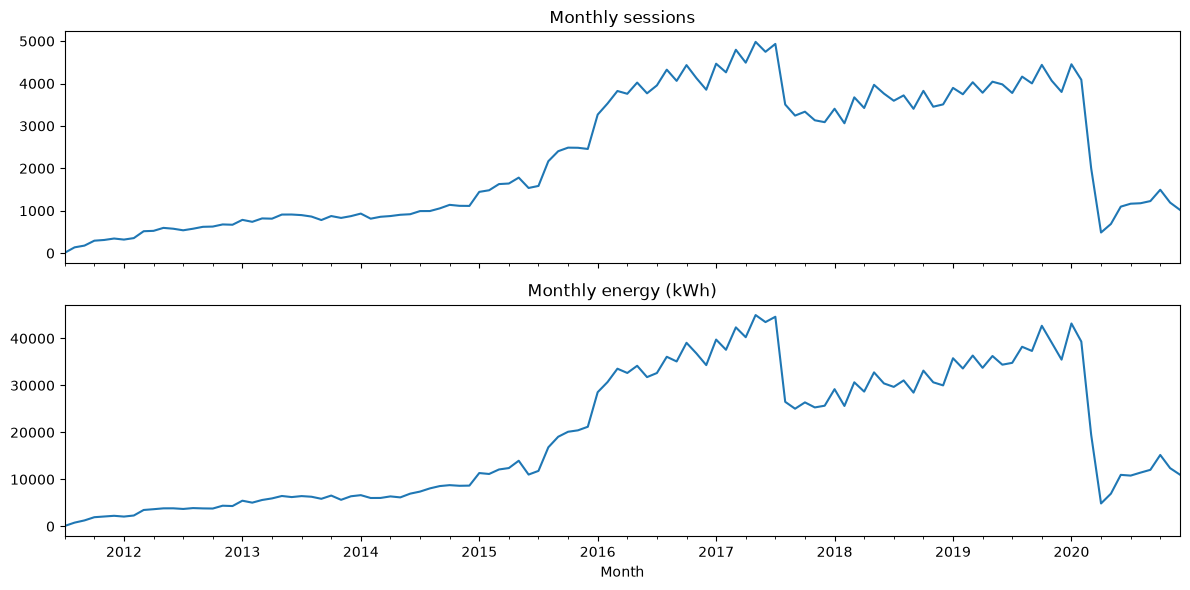

In [29]:
monthly = df.groupby("Month").agg(sessions=("Energy (kWh)", "size"),
                                  energy=("Energy (kWh)", "sum"))
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
monthly["sessions"].plot(ax=ax[0], title="Monthly sessions")
monthly["energy"].plot(ax=ax[1], title="Monthly energy (kWh)")
plt.tight_layout(); plt.show()

Usage grew steadily until mid-2017, dropped when fees were introduced, and fell sharply in March 2020 due to COVID-19. Since the test set covers the last 30% of the data, it will include this unusual COVID period.

# 2.3 Charging Patterns by Hour and Weekday

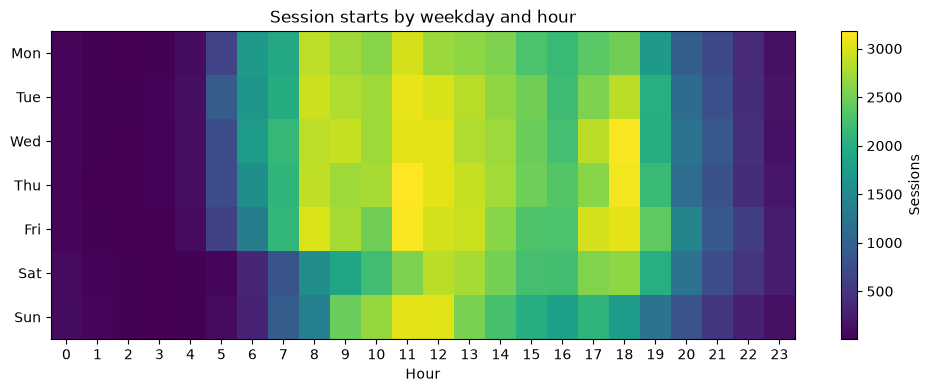

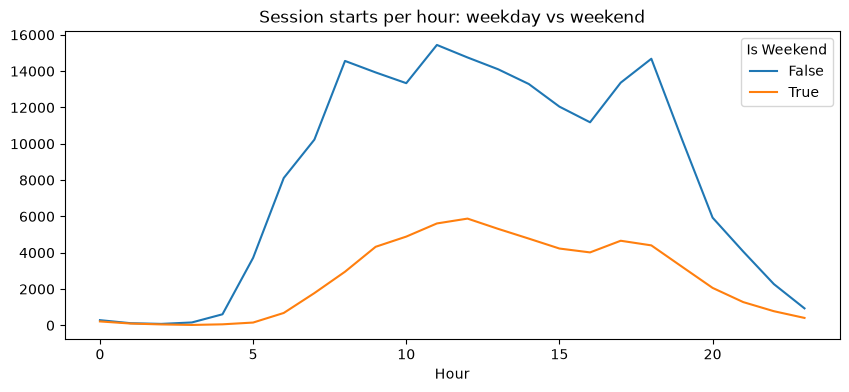

In [30]:
pivot = df.pivot_table(index="Weekday", columns="Hour",
                       values="Energy (kWh)", aggfunc="size")
plt.figure(figsize=(12, 4))
plt.imshow(pivot, aspect="auto", cmap="viridis")
plt.yticks(range(7), ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"])
plt.xticks(range(24)); plt.colorbar(label="Sessions")
plt.title("Session starts by weekday and hour"); plt.xlabel("Hour"); plt.show()

df.groupby(["Is Weekend", "Hour"]).size().unstack(0).plot(
    figsize=(10, 4), title="Session starts per hour: weekday vs weekend")
plt.show()

Weekdays have much more activity than weekends, with peaks around 8 am, noon and 5–6 pm, while weekends show a flatter profile peaking around noon. This supports using hour and weekday as features for clustering and prediction.

# 2.4 Energy and Duration Distributions

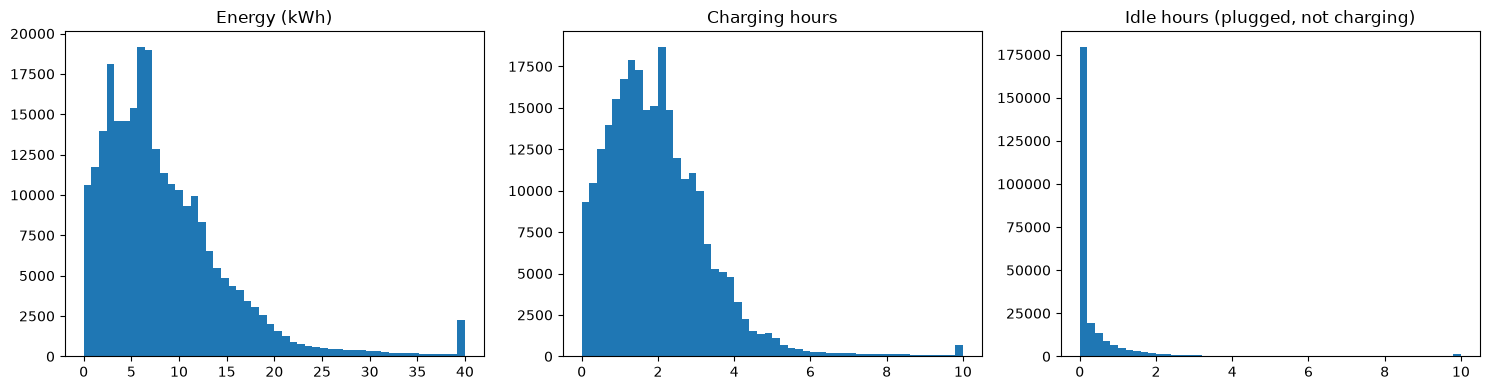

        Energy (kWh)  Charging Hours     Idle Hours
count  259335.000000   259335.000000  259335.000000
mean        8.542384        1.998667       0.488362
std         7.178741        1.381493       1.479172
min         0.010000        0.001667       0.000000
25%         3.784438        1.040000       0.003889
50%         6.868316        1.816389       0.007222
75%        11.457716        2.697222       0.354722
max        97.360000       22.931944     112.547222


In [31]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(df["Energy (kWh)"].clip(upper=40), bins=50); ax[0].set_title("Energy (kWh)")
ax[1].hist(df["Charging Hours"].clip(upper=10), bins=50); ax[1].set_title("Charging hours")
ax[2].hist(df["Idle Hours"].clip(upper=10), bins=50); ax[2].set_title("Idle hours (plugged, not charging)")
plt.tight_layout(); plt.show()
print(df[["Energy (kWh)", "Charging Hours", "Idle Hours"]].describe())

All three variables are right-skewed: most sessions use 2–12 kWh and charge for under 4 hours. Most sessions have almost no idle time, but a long tail of vehicles stays plugged in for many hours after charging ends.

# 2.5 Station Analysis

Number of stations: 47


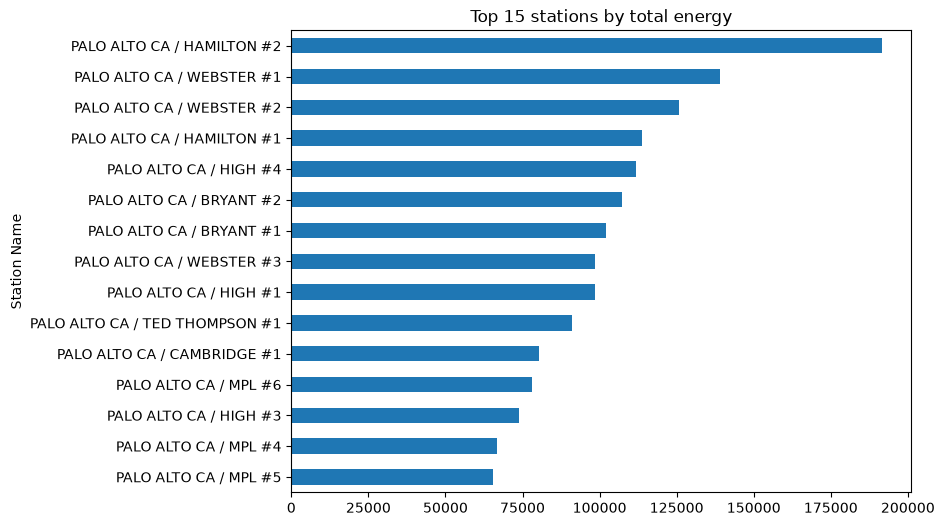

In [32]:
station = df.groupby("Station Name").agg(sessions=("Energy (kWh)", "size"),
                                         energy=("Energy (kWh)", "sum"),
                                         avg_idle=("Idle Hours", "mean"))
print("Number of stations:", len(station))
station.sort_values("energy", ascending=False).head(15)["energy"].plot.barh(
    figsize=(8, 6), title="Top 15 stations by total energy")
plt.gca().invert_yaxis(); plt.show()

Demand is uneven across stations, with HAMILTON #2 having by far the highest total energy. Totals also depend on how long each station has been active.

# 2.6 User Analysis

count    21418.000000
mean        11.748202
std         44.829854
min          1.000000
25%          1.000000
50%          2.000000
75%          5.000000
max       1115.000000
dtype: float64
Users with only 1 session: 43.67821458586236 %


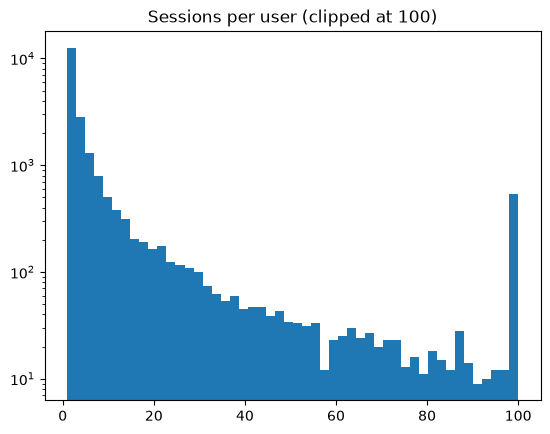

In [33]:
user_sessions = df.dropna(subset=["User ID"]).groupby("User ID").size()
print(user_sessions.describe())
print("Users with only 1 session:", (user_sessions == 1).mean() * 100, "%")
plt.hist(user_sessions.clip(upper=100), bins=50)
plt.title("Sessions per user (clipped at 100)"); plt.yscale("log"); plt.show()

43.7% of users charged only once and half of the users charged at most 2 times, while the most active user had 1,115 sessions. Only users with a minimum number of sessions will be included in the clustering.

# 2.7 Idle Time (Hoarding) and Fees

Share of sessions with >1h idle: 12.072030385408834 %


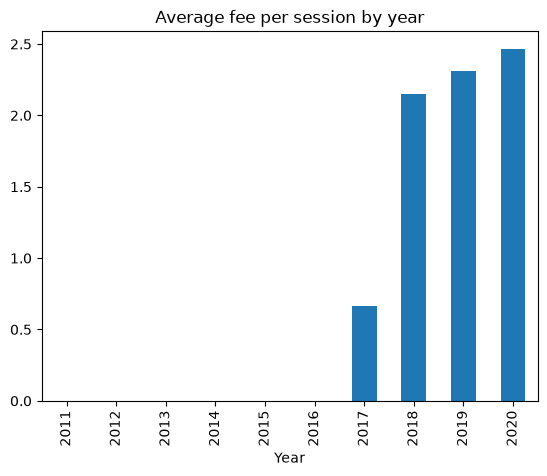

In [34]:
print("Share of sessions with >1h idle:", (df["Idle Hours"] > 1).mean() * 100, "%")
df.groupby("Year")["Fee"].mean().plot.bar(title="Average fee per session by year")
plt.show()

About 12% of sessions have more than 1 hour of idle time ("hoarding"). Charging was free until 2017, after which the average fee rose to about 2.5 USD per session by 2020.

# 3. TASK 1: USER CLUSTERING

# 3.1 Hourly Transformation
Each session is split into the hours it covers. For each hour we compute the occupancy (fraction of the hour the vehicle was plugged in) and the energy consumed, assuming a constant charging rate from the start of the session until the end of the charging time.

In [35]:
def split_session(start, total_hours, charging_hours, energy):
    plug_end = start + pd.Timedelta(hours=total_hours)
    charge_end = start + pd.Timedelta(hours=charging_hours)
    rows = []
    for hour in pd.date_range(start.floor("h"), plug_end.floor("h"), freq="h"):
        hour_end = hour + pd.Timedelta(hours=1)
        begin = max(start, hour)
        occupancy = (min(plug_end, hour_end) - begin).total_seconds() / 3600
        charged = max((min(charge_end, hour_end) - begin).total_seconds() / 3600, 0)
        rows.append((hour, energy * charged / charging_hours, occupancy))
    return rows

data = []
for station, user, start, total, charging, energy in zip(
        df["Station Name"], df["User ID"], df["Start Date"],
        df["Total Hours"], df["Charging Hours"], df["Energy (kWh)"]):
    for hour, e, occ in split_session(start, total, charging, energy):
        data.append((station, user, hour, e, occ))

hourly = pd.DataFrame(data, columns=["Station Name", "User ID", "Hour", "Energy", "Occupancy"])

print("Original total energy:", round(df["Energy (kWh)"].sum(), 1))
print("Hourly total energy:  ", round(hourly["Energy"].sum(), 1))
hourly.head()

Original total energy: 2215339.1
Hourly total energy:   2215339.1


,Station Name,User ID,Hour,Energy,Occupancy
0,PALO ALTO CA / HAMILTON #1,3284,2011-07-29 20:00:00,2.356218,0.716667
1,PALO ALTO CA / HAMILTON #1,3284,2011-07-29 21:00:00,3.287746,1.000000
2,PALO ALTO CA / HAMILTON #1,3284,2011-07-29 22:00:00,0.605493,1.000000
3,PALO ALTO CA / HAMILTON #1,3284,2011-07-29 23:00:00,0.000000,0.342222
4,PALO ALTO CA / HAMILTON #1,4169,2011-07-30 00:00:00,0.106588,0.035000


The total energy is the same before and after the transformation, which confirms that the energy was split correctly across hours.

In [36]:
energy_ts = hourly.pivot_table(index="Hour", columns="Station Name",
                               values="Energy", aggfunc="sum").asfreq("h").fillna(0)
occupancy_ts = hourly.pivot_table(index="Hour", columns="Station Name",
                                  values="Occupancy", aggfunc="sum").asfreq("h").fillna(0)

print("Hourly time series shape:", energy_ts.shape)
energy_ts.head()

Hourly time series shape: (82647, 47)


Station Name,PALO ALTO CA / BRYANT # 1,PALO ALTO CA / BRYANT #1,PALO ALTO CA / BRYANT #2,PALO ALTO CA / BRYANT #3,PALO ALTO CA / BRYANT #4,PALO ALTO CA / BRYANT #5,PALO ALTO CA / BRYANT #6,PALO ALTO CA / CAMBRIDGE #1,PALO ALTO CA / CAMBRIDGE #2,PALO ALTO CA / CAMBRIDGE #3,...,PALO ALTO CA / SHERMAN 7,PALO ALTO CA / SHERMAN 8,PALO ALTO CA / SHERMAN 9,PALO ALTO CA / TED THOMPSON #1,PALO ALTO CA / TED THOMPSON #2,PALO ALTO CA / TED THOMPSON #3,PALO ALTO CA / TED THOMPSON #4,PALO ALTO CA / WEBSTER #1,PALO ALTO CA / WEBSTER #2,PALO ALTO CA / WEBSTER #3
Hour,,,,,,,,,,,,,,,,,,,,,
2011-07-29 20:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-07-29 21:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-07-29 22:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-07-29 23:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-07-30 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


We now have two hourly time series per station: energy (kWh) and occupancy (number of plugs in use, on average, during the hour). Hours with no sessions are set to 0. Note that stations installed later have zeros before their installation date.

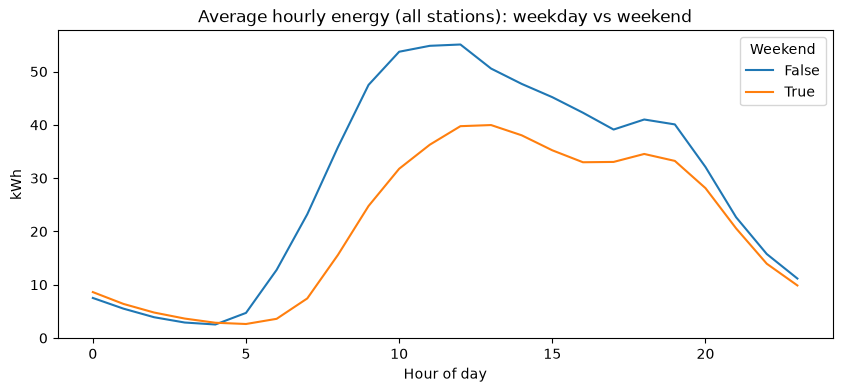

In [37]:
profile = energy_ts.sum(axis=1).to_frame("Energy")
profile["Hour of day"] = profile.index.hour
profile["Weekend"] = profile.index.dayofweek >= 5

profile.groupby(["Hour of day", "Weekend"])["Energy"].mean().unstack().plot(
    figsize=(10, 4), title="Average hourly energy (all stations): weekday vs weekend")
plt.ylabel("kWh"); plt.show()

The average hourly energy profile follows the same daily pattern as the session start times in Section 2.3, with higher demand on weekdays during working hours.

3.2 Users Features

In [38]:
user_hourly = hourly.dropna(subset=["User ID"]).copy()
user_hourly["Period"] = pd.cut(user_hourly["Hour"].dt.hour, bins=[0, 6, 12, 18, 24], right=False,
                               labels=["Night", "Morning", "Afternoon", "Evening"])
user_hourly["Weekend"] = user_hourly["Hour"].dt.dayofweek >= 5

period_share = user_hourly.pivot_table(index="User ID", columns="Period", values="Energy",
                                       aggfunc="sum", observed=False)
period_share = period_share.div(period_share.sum(axis=1), axis=0)

total_energy = user_hourly.groupby("User ID")["Energy"].sum()
weekend_energy = user_hourly[user_hourly["Weekend"]].groupby("User ID")["Energy"].sum()
weekend_share = (weekend_energy / total_energy).fillna(0).rename("Weekend")

In [39]:
session_stats = df.dropna(subset=["User ID"]).groupby("User ID").agg(
    Sessions=("Energy (kWh)", "size"),
    Avg_Energy=("Energy (kWh)", "mean"),
    Avg_Charging_Hours=("Charging Hours", "mean"),
    Avg_Idle_Hours=("Idle Hours", "mean"),
    Stations_Used=("Station Name", "nunique"))

users = session_stats.join(period_share).join(weekend_share)
users.columns = [str(c) for c in users.columns]
users = users[users["Sessions"] >= 5]

print("Users kept for clustering:", len(users))
users.describe()

Users kept for clustering: 5975


,Sessions,Avg_Energy,Avg_Charging_Hours,Avg_Idle_Hours,Stations_Used,Night,Morning,Afternoon,Evening,Weekend
count,5975.000000,5975.000000,5975.000000,5975.000000,5975.000000,5975.000000,5975.000000,5975.000000,5975.000000,5975.000000
mean,37.852218,7.779461,1.732436,0.339775,5.793640,0.014297,0.222658,0.458590,0.304456,0.302968
std,79.103764,5.246157,0.914811,0.627115,3.545122,0.061180,0.241199,0.248035,0.276892,0.288418
min,5.000000,0.019714,0.005278,0.001667,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7.000000,4.475895,1.128181,0.026022,3.000000,0.000000,0.025555,0.266883,0.046141,0.016949
50%,13.000000,6.556714,1.546128,0.147889,5.000000,0.000000,0.142255,0.451469,0.240275,0.241152
75%,31.000000,9.539276,2.119911,0.393366,7.000000,0.000000,0.339917,0.641125,0.503712,0.502536
max,1115.000000,56.407302,9.595302,10.646911,32.000000,0.836317,1.000000,1.000000,1.000000,1.000000


3.3 Scaling

In [40]:
from sklearn.preprocessing import StandardScaler

features = users.dropna().copy()
features["Sessions"] = np.log1p(features["Sessions"])
features["Avg_Idle_Hours"] = np.log1p(features["Avg_Idle_Hours"])

scaler = StandardScaler()
X = scaler.fit_transform(features)

print("Shape:", X.shape)
pd.DataFrame(X, columns=features.columns).describe().round(2)

Shape: (5975, 10)


,Sessions,Avg_Energy,Avg_Charging_Hours,Avg_Idle_Hours,Stations_Used,Night,Morning,Afternoon,Evening,Weekend
count,5975.00,5975.00,5975.00,5975.00,5975.00,5975.00,5975.00,5975.00,5975.00,5975.00
mean,0.00,-0.00,0.00,0.00,-0.00,-0.00,-0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.07,-1.48,-1.89,-0.79,-1.35,-0.23,-0.92,-1.85,-1.10,-1.05
25%,-0.80,-0.63,-0.66,-0.71,-0.79,-0.23,-0.82,-0.77,-0.93,-0.99
50%,-0.26,-0.23,-0.20,-0.33,-0.22,-0.23,-0.33,-0.03,-0.23,-0.21
75%,0.53,0.34,0.42,0.32,0.34,-0.23,0.49,0.74,0.72,0.69
max,3.93,9.27,8.60,7.52,7.39,13.44,3.22,2.18,2.51,2.42


After scaling, all features have a mean of 0 and a standard deviation of 1, so no single feature dominates the clustering.

3.4 K means

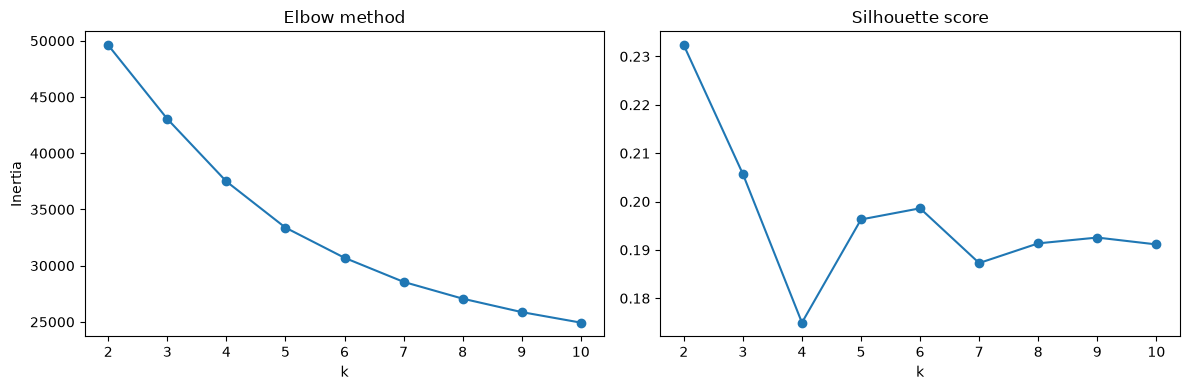

In [41]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 11)
inertias = []
silhouettes = []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X, labels, sample_size=5000, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k_values, inertias, marker="o"); ax[0].set_title("Elbow method"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia")
ax[1].plot(k_values, silhouettes, marker="o"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

We choose k = 2 because it has the highest silhouette score.

In [42]:
k = 2

kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
features["KMeans Cluster"] = kmeans.fit_predict(X)

print(features["KMeans Cluster"].value_counts().sort_index())
users.loc[features.index].groupby(features["KMeans Cluster"]).mean().round(2)

KMeans Cluster
0    4058
1    1917
Name: count, dtype: int64


,Sessions,Avg_Energy,Avg_Charging_Hours,Avg_Idle_Hours,Stations_Used,Night,Morning,Afternoon,Evening,Weekend
KMeans Cluster,,,,,,,,,,
0,15.79,5.92,1.35,0.19,5.23,0.00,0.14,0.48,0.38,0.37
1,84.55,11.71,2.54,0.65,6.99,0.04,0.39,0.42,0.15,0.16
